# Proofs {#sec-proofs}

In this section, we introduce the proofs to several claims made in our paper. First, we prove the equivalence between weights-DDRL and asymmetric RL in a multi-armed bandit task, in the limit of an infinitely small discretization $\sigma$. Second, we show that optimism can shift the separatrix in a stag-hunt game, but not in a prisoner's dilemma.

## Equivalence between weights-DDRL and asymmetric RL in a two-armed bandit task

We consider a multi-armed bandit with arms $a_i$, $i \in N$; for each $i$, $a_i$ yields a reward, $+1$, with probability $p_i$, and a punishment, $-1$, with probability $1-p_i$. 

An asymmetric RL agent is equipped with two different learning rates: $\alpha^{+}$ updates positive prediction errors, and $\alpha^{-}$ updates negative prediction errors. The agent's bias strength, $b$, is defined as the learning-rate ratio: $b = \frac{\alpha^{+}}{\alpha^{-}}$. Cazé and van der Meer (2013) have shown that, for such an agent, the Q-value at steady state for arm $a_{i}$ can be expressed as follows:

\begin{equation}
    Q^{a_i}_{\infty} = \frac{bp_i - (1-p_i)}{bp_i + (1-p_i)}
\end{equation}

Let us consider a weights-DDRL agent with number of neurons $n$, discretization sigma $\sigma$, discretization grid ${x_j, j \in [1, n]}$ with width $\Delta x$, and weight vector $\boldsymbol{w}$ with elements $w_j$, $j \in [1, n]$. For each arm $a_i$, this agent computes a Q-value distribution $Q^{a_i, v}$, which quantifies the probability that the Q-value of arm $a_i$ equals a value $v$. Since the two-armed bandit is a stateless environment, the Q-value distribution $Q^{a_i, v}$ equals the reward distribution $R^{a_i, r}$, which quantifies the probability that arm $a_{i}$ yields a reward $r$. 

Therefore, in the limit of an infinitely small discretization sigma $\sigma \rightarrow 0$, the Q-value distribution for arm $a_i$ can be described as follows:

* $ Q^{a_i, v} = p_i $ when $v = 1$
* $ Q^{a_i, v} = 1 - p_i $ when $v = -1$
* $ Q^{a_i, v} = 0 $ for all other values of $v$.

This is assuming that the agent is neutral -- that is, all elements $w_j$ of vector $\boldsymbol{w}$ have value $1$. Now, let us consider an optimistic/pessimistic agent. For such an agent, $w_j = 1$ if $x_j < \bar Q^{a_i, v}$, and $w_j = w_U$ if $x_j \geq \bar Q^{a_i, v}$, where $\bar Q^{a_i, v}$ denotes the mean of the Q-value distribution. 

The mean of the Q-value distribution is $\bar Q^{a_i, v} = 2p_i - 1$, hence $\bar Q^{a_i, v} \in [-1, 1]$. Excluding the extreme case in which there is an $i$, such that $p_i = 1$, we can formulate the weighted Q-value distribution $\tilde Q^{a_i, v}$:

* $\tilde Q^{a_i, v} = w_U p_i $ when $v = 1$
* $\tilde Q^{a_i, v} = 1 - p_i $ when $v = -1$
* $\tilde Q^{a_i, v} = 0 $ for all other values of $v$.

We then normalize this distribution so that $\int_{x_1 - \frac{\Delta x}{2}}^{x_n+\frac{\Delta x}{2}}\tilde Q^{a_i, v} dv = 1$. To do this, we divide the distribution by its integral, hence:

* $\tilde Q^{a_i, v} = \frac{w_U p_i}{w_U p_i + (1-p_i)} $ when $v = 1$
* $\tilde Q^{a_i, v} = \frac{1 - p_i}{w_U p_i + (1-p_i)} $ when $v = -1$
* $\tilde Q^{a_i, v} = 0 $ for all other values of $v$.

The mean of this new distribution is:
\begin{equation}
    \overset{\simeq} Q^{a_i, v} = \frac{w_U p_i}{w_U p_i + (1-p_i)} - \frac{1 - p_i}{w_U p_i + (1-p_i)} \\
    = \frac{w_U p_i - (1 - p_i)}{w_U p_i + (1-p_i)}
\end{equation}

Thus, on a multi-armed bandit task, an asymmetric-RL agent with bias strength $b$ learns the same Q-values at steady state as a weights-DDRL agent with upper weight value $w_U = b$.


## Effect of optimism on social dilemmas

We consider the following social dilemma, in which two agents can cooperate ($c$) or defect ($d$).

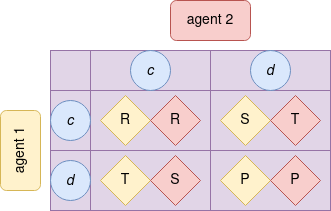

Mutual cooperation yields a "reward" $R$ for both agents, while mutual defection yields a "punishment" $P$. If one agent cooperates and the other defects, the cooperator gets a "sucker" payoff $S$, while the defector gets a "temptation" payoff $T$. The stag-hunt game and the prisoner's dilemma differ in their reward structure:

* In a stag-hunt game, $R>T>P>S$;
* In a prisoner's dilemma, $T>R>P>S$.

We want to find the conditions under which the Q-value of cooperation for agent $i$, $Q^{i,c}$, is greater than the Q-value for defection for agent $i$, $Q^{i,d}$. To do this, we consider a weights-DDRL agent with number of neurons $n$, discretization sigma $\sigma$, discretization grid ${x_j, j \in [1, n]}$ with width $\Delta x$, and weight vector $\boldsymbol{w}$ with elements $w_j$, $j \in [1, n]$. Moreover, we place ourselves in the limit of an infinitely small discretization sigma, $\sigma \rightarrow 0$, and we assume the agent's discount factor $\gamma$ is $0$. As a consequence, the Q-value distributions $Q^{i,c,v}$ and $Q^{i,d,v}$ just depend on the payoff and on the other agent $j$'s strategy $X^{j,c}$.

* $Q^{i,c,v} = R$ with probability $X^{j,c}$;
* $Q^{i,c,v} = S$ with probability $1 - X^{j,c}$;
* $Q^{i,d,v} = P$ with probability $X^{j,d} = 1 - X^{j,c}$;
* $Q^{i,d,v} = T$ with probability $1 - X^{j,d} = X^{j,c}$.

The mean Q-value $\bar Q^{i,c,v}$ is therefore $X^{j,c} \cdot R + (1 - X^{j,c}) \cdot S = S + X^{j,c} (R - S)$. We consider $X^{j,c} \in ]0,1[$. In both social dilemmas, $R > S$, from which it follows that $S < \bar Q^{i,c,v} < R$. As a consequence, the biased and normalized distribution $\tilde Q^{i,c,v}$ is described by:

* $Q^{i,c,v} = R$ with probability $\frac{w_U \cdot X^{j,c}}{w_U \cdot X^{j,c} + (1 - X^{j,c})}$;
* $Q^{i,c,v} = S$ with probability $\frac{1 - X^{j,c}}{w_U \cdot X^{j,c} + (1 - X^{j,c})}$.

A similar reasoning can be applied to the Q-value distribution $Q^{i,d,v}$, and we obtain:

* $Q^{i,d,v} = P$ with probability $\frac{1 - X^{j,c}}{w_U \cdot X^{j,c} + (1 - X^{j,c})}$;
* $Q^{i,d,v} = T$ with probability $\frac{w_U \cdot X^{j,c}}{w_U \cdot X^{j,c} + (1 - X^{j,c})}$.

Consequently, the means of these biased distributions are:

\begin{equation}
    \overset{\simeq} Q^{i,c,v} = \frac{w_U \cdot X^{j,c} \cdot R + (1 - X^{j,c})\cdot S}{w_U \cdot X^{j,c} + (1 - X^{j,c})}\\
    = \frac{X^{j,c} \cdot (w_U \cdot R - S) + S}{X^{j,c} \cdot (w_U - 1) + 1}
\end{equation}

\begin{equation}
    \overset{\simeq} Q^{i,d,v} = \frac{w_U \cdot X^{j,c} \cdot T + (1 - X^{j,c})\cdot P}{w_U \cdot X^{j,c} + (1 - X^{j,c})}\\
    = \frac{X^{j,c} \cdot (w_U \cdot T - P) + P}{X^{j,c} \cdot (w_U - 1) + 1}
\end{equation}

We have $\overset{\simeq} Q^{i,c,v} \geq \overset{\simeq} Q^{i,c,d}$

iff $X^{j,c} \cdot (w_U \cdot R - S) + S \geq X^{j,c} \cdot (w_U \cdot T - P) + P$

iff $X^{j,c} \cdot [w_U (R-T) + (P-S)] + (S-P) \geq 0$

iff $X^{j,c} \cdot [w_U (R-T)] + (S-P)[1 - X^{j,c}] \geq 0$.

In both social dilemmas, $P > S$ so $S-P < 0$. Therefore, $(S-P)[1 - X^{j,c}] < 0$.

In a prisoner's dilemma, $T > R$, so $R-T < 0$, and as a consequence, $X^{j,c} \cdot [w_U (R-T)] < 0$. Therefore, in a prisoner's dilemma, it is not possible to have $\overset{\simeq} Q^{i,c,v} \geq \overset{\simeq} Q^{i,c,d}$. In other terms, the agents always mutually defect.

In a stag-hunt game, however, $R > T$, so $R-T > 0$, and as a consequence, $X^{j,c} \cdot [w_U (R-T)] > 0$. So we have $\overset{\simeq} Q^{i,c,v} \geq \overset{\simeq} Q^{i,c,d}$

iff $w_U (R-T) \geq \frac{(P-S)(1 - X^{j,c})}{X^{j,c}}$

iff $w_U \geq \frac{(P-S)(1 - X^{j,c})}{(R-T)X^{j,c}}$.

Therefore, in a stag-hunt game, optimism/pessimism has an effect on cooperation. 

We can plot $w_U$ as a function of $X^{j,c}$ for the stag-hunt game we investigate in our paper, that is: $R=3$, $T=1$, $P=0$, and $S=-2$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def w_coop(X, R=3, T=1, P=0, S=-2):
    return (P-S) * (1-X) / ((R-T) * X)

<matplotlib.legend.Legend>

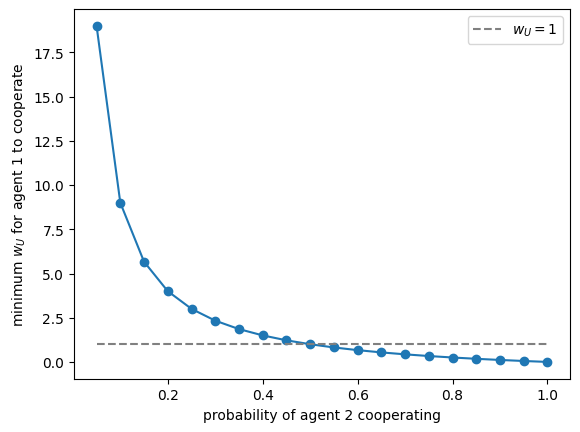

In [ ]:
X = np.linspace(0.05, 1, 20)
ws = w_coop(X)
ones = np.ones((len(X)))

plt.plot(X, ws, 'o-')
plt.plot(X, ones, '--', color="gray", label=r'$w_U = 1$')
plt.xlabel("probability of agent 2 cooperating")
plt.ylabel("minimum "+r'$w_U$'+" for agent 1 to cooperate")
plt.legend()